# Proyecto 2 — Modelado y Resultados
**Tema 10: Chatbot Arena — predicción de preferencia humana (A / B / empate).**

Este cuaderno continúa el trabajo del análisis exploratorio (`ChatbotArena.ipynb`).
Reconstruye las variables derivadas del EDA y, sobre ellas, entrena, ajusta y compara
varios modelos de clasificación multiclase. La métrica principal es la **pérdida
logarítmica (log loss)**, la misma de la competencia de Kaggle.

> Nota: ejecútalo en el entorno donde esté disponible `train.csv` (Colab/Kaggle o local).
> Al final guarda los modelos entrenados, las predicciones de prueba y las figuras de
> resultados para el informe y la aplicación.

## 0. Dependencias

In [35]:
import json, re, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (log_loss, accuracy_score, f1_score,
                             confusion_matrix, classification_report)
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
RANDOM_STATE = 42
CLASSES = ['A', 'B', 'tie']   # orden fijo de clases para todas las probabilidades

OUTPUT_DIR = Path('resultados_modelado')   # figuras, modelos y predicciones
OUTPUT_DIR.mkdir(exist_ok=True)
print('Salidas en:', OUTPUT_DIR.resolve())

Salidas en: /Users/brandon/Documents/UVG/data/Proyecto2-Data-Science/notebooks/resultados_modelado


## 1. Carga del conjunto de datos

In [36]:
# Mismas ubicaciones candidatas que en el EDA
candidates = [Path('LMSYS Chatbot Arena/train.csv'), Path('data/train.csv'), Path('train.csv'),
              Path('../data/train.csv'), Path('/kaggle/input/lmsys-chatbot-arena/train.csv')]
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, 'No se encontró train.csv — colócalo en una de las rutas candidatas.'
print('Usando:', DATA_PATH)

raw = pd.read_csv(DATA_PATH)
print('Filas x columnas:', raw.shape)

Usando: ../data/train.csv
Filas x columnas: (57477, 9)


## 2. Limpieza y reconstrucción de variables
Se replica la lógica del EDA para que este cuaderno sea autónomo: se decodifican las
conversaciones (listas JSON), se define el objetivo `winner` (A/B/tie) y se calculan las
variables cuantitativas derivadas del texto (longitud, palabras, elementos de formato).

In [37]:
df = raw.copy()

# Objetivo
df = df.drop_duplicates(subset=df.columns.difference(['id']).tolist()).reset_index(drop=True)
df['winner'] = np.select([df.winner_model_a == 1, df.winner_model_b == 1], ['A', 'B'], default='tie')

# Decodificación de las conversaciones
def decode(s):
    try:
        lst = json.loads(s)
    except Exception:
        return [str(s)]
    return [('' if x is None else str(x)) for x in lst]

for c in ['prompt', 'response_a', 'response_b']:
    df[c + '_text'] = df[c].map(decode).map(lambda l: '\n'.join(l))
df['n_turns'] = df['prompt'].map(decode).map(len)

# Variables estructurales derivadas del texto
re_code   = re.compile(r'```')
re_list   = re.compile(r'^\s*(?:[-*\u2022]|\d+[.)])\s+', re.M)
re_header = re.compile(r'^\s*#{1,6}\s+', re.M)
re_bold   = re.compile(r'\*\*[^*]+\*\*')

def text_feats(t):
    return dict(len=len(t), words=len(t.split()),
                code=len(re_code.findall(t)) // 2, lists=len(re_list.findall(t)),
                headers=len(re_header.findall(t)), bold=len(re_bold.findall(t)))

for side in ['a', 'b']:
    f = pd.DataFrame(df[f'response_{side}_text'].map(text_feats).tolist())
    for col in f.columns:
        df[f'{col}_{side}'] = f[col].values

df['prompt_len']   = df['prompt_text'].str.len()
df['prompt_words'] = df['prompt_text'].str.split().str.len()
df['fmt_a'] = df[['code_a', 'lists_a', 'headers_a', 'bold_a']].sum(axis=1)
df['fmt_b'] = df[['code_b', 'lists_b', 'headers_b', 'bold_b']].sum(axis=1)

print('Distribución del objetivo:')
print(df['winner'].value_counts(normalize=True).round(3))

Distribución del objetivo:
winner
A      0.349
B      0.342
tie    0.309
Name: proportion, dtype: float64


### 2.1 Variables comparativas A vs B
Como el objetivo es qué respuesta se prefiere, las variables más informativas son las que
**comparan** A con B (diferencias y razones), no sus valores absolutos. Esto además hace el
modelo menos sensible a la posición.

In [38]:
eps = 1.0
df['len_diff']     = df['len_a'] - df['len_b']
df['len_ratio']    = np.log((df['len_a'] + eps) / (df['len_b'] + eps))
df['words_diff']   = df['words_a'] - df['words_b']
df['fmt_diff']     = df['fmt_a'] - df['fmt_b']
df['code_diff']    = df['code_a'] - df['code_b']
df['lists_diff']   = df['lists_a'] - df['lists_b']
df['headers_diff'] = df['headers_a'] - df['headers_b']
df['bold_diff']    = df['bold_a'] - df['bold_b']
df['a_is_longer']  = (df['len_a'] > df['len_b']).astype(int)

NUM_FEATURES = ['n_turns', 'prompt_len', 'prompt_words',
                'len_a', 'len_b', 'words_a', 'words_b', 'fmt_a', 'fmt_b',
                'len_diff', 'len_ratio', 'words_diff', 'fmt_diff',
                'code_diff', 'lists_diff', 'headers_diff', 'bold_diff', 'a_is_longer']
print(len(NUM_FEATURES), 'variables numéricas para los modelos')

18 variables numéricas para los modelos


## 3. Selección de los conjuntos de entrenamiento y prueba
Partición **estratificada** 80/20 sobre el objetivo, para conservar la proporción de
A / B / empate en ambos conjuntos. La semilla fija (`RANDOM_STATE`) hace reproducible el
experimento. El conjunto de prueba no se toca hasta la evaluación final; el ajuste de
hiperparámetros usa validación cruzada **dentro** del entrenamiento.

In [39]:
y = df['winner'].values
X = df   # se seleccionan columnas por modelo más abajo

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print('Entrenamiento:', X_train.shape[0], ' Prueba:', X_test.shape[0])
print(pd.Series(y_train).value_counts(normalize=True).round(3).to_dict())

Entrenamiento: 45976  Prueba: 11494
{'A': 0.349, 'B': 0.342, 'tie': 0.309}


## 4. Utilidades de evaluación
Todas las probabilidades se alinean al orden fijo `CLASSES = ['A','B','tie']`. Se reportan
log loss (métrica principal), exactitud y F1 macro, además del tiempo de entrenamiento.

In [40]:
resultados = []   # una fila por modelo

def proba_ordenada(modelo, X_):
    """predict_proba reordenado a CLASSES, sin importar el orden interno del modelo."""
    p = modelo.predict_proba(X_)
    cols = list(modelo.classes_)
    idx = [cols.index(c) for c in CLASSES]
    return p[:, idx]

def evaluar(nombre, modelo, X_tr, X_te, t_fit):
    proba = proba_ordenada(modelo, X_te)
    pred = np.array(CLASSES)[proba.argmax(axis=1)]
    fila = dict(
        modelo=nombre,
        log_loss=log_loss(y_test, proba, labels=CLASSES),
        accuracy=accuracy_score(y_test, pred),
        f1_macro=f1_score(y_test, pred, average='macro'),
        seg_entrenamiento=round(t_fit, 1),
    )
    resultados.append(fila)
    print(f"{nombre:<28} log_loss={fila['log_loss']:.4f}  acc={fila['accuracy']:.4f}  "
          f"f1={fila['f1_macro']:.4f}  ({fila['seg_entrenamiento']} s)")
    return proba, pred

## 5. Modelos

### 5.0 Línea base (clase a priori)
Predice siempre la distribución de clases del entrenamiento. Su log loss ≈ ln(3) ≈ 1.0986
es la referencia mínima que cualquier modelo útil debe superar.

In [41]:
t0 = time.time()
base = DummyClassifier(strategy='prior')
base.fit(X_train[NUM_FEATURES], y_train)
evaluar('Línea base (prior)', base, X_train[NUM_FEATURES], X_test[NUM_FEATURES], time.time() - t0)

Línea base (prior)           log_loss=1.0972  acc=0.3491  f1=0.1725  (0.0 s)


(array([[0.34909518, 0.34189577, 0.30900905],
        [0.34909518, 0.34189577, 0.30900905],
        [0.34909518, 0.34189577, 0.30900905],
        ...,
        [0.34909518, 0.34189577, 0.30900905],
        [0.34909518, 0.34189577, 0.30900905],
        [0.34909518, 0.34189577, 0.30900905]], shape=(11494, 3)),
 array(['A', 'A', 'A', ..., 'A', 'A', 'A'], shape=(11494,), dtype='<U3'))

### 5.1 Regresión logística sobre variables estructurales
Modelo lineal e interpretable sobre las variables derivadas (longitud, formato, turnos).
Captura directamente los sesgos de verbosidad y de formato detectados en el EDA.

In [42]:
logit_struct = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=2000, C=1.0, random_state=RANDOM_STATE)),
])
t0 = time.time()
logit_struct.fit(X_train[NUM_FEATURES], y_train)
evaluar('LogReg estructural', logit_struct, X_train[NUM_FEATURES], X_test[NUM_FEATURES], time.time() - t0)

LogReg estructural           log_loss=1.0654  acc=0.4341  f1=0.3650  (0.1 s)


(array([[0.27821003, 0.39873692, 0.32305305],
        [0.41647351, 0.29039499, 0.2931315 ],
        [0.38679894, 0.28491211, 0.32828895],
        ...,
        [0.23456551, 0.45663186, 0.30880263],
        [0.50201983, 0.1971997 , 0.30078047],
        [0.29206029, 0.42996228, 0.27797743]], shape=(11494, 3)),
 array(['B', 'A', 'A', ..., 'B', 'A', 'B'], shape=(11494,), dtype='<U3'))

### 5.2 Regresión logística sobre texto (TF-IDF) + estructura
Añade el contenido de las respuestas. Se vectorizan A y B por separado con TF-IDF
(1–2 gramas) y se combinan con las variables numéricas en un `ColumnTransformer`.
Se usa **regularización fuerte** (`C=0.3`) y se **calibran las probabilidades**
(sigmoide, 3 pliegues): sin esto el modelo queda sobreconfiado y su log loss supera
la de la línea base pese a tener buena exactitud.

In [43]:
# TF-IDF de A y B por separado + variables estructurales
pre_texto = ColumnTransformer([
    ('tfidf_a', TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, sublinear_tf=True), 'response_a_text'),
    ('tfidf_b', TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=5, sublinear_tf=True), 'response_b_text'),
    ('num', StandardScaler(), NUM_FEATURES),
])

# C bajo = regularización L2 fuerte: evita coeficientes extremos y probabilidades sobreconfiadas
logit_texto_base = Pipeline([
    ('pre', pre_texto),
    ('clf', LogisticRegression(max_iter=2000, C=0.3, random_state=RANDOM_STATE)),
])

# Calibración de probabilidades (Platt/sigmoide, validación cruzada de 3 pliegues)
logit_texto = CalibratedClassifierCV(logit_texto_base, method='sigmoid', cv=3)

cols_texto = ['response_a_text', 'response_b_text'] + NUM_FEATURES
t0 = time.time()
logit_texto.fit(X_train[cols_texto], y_train)
evaluar('LogReg TF-IDF + estructura', logit_texto, X_train[cols_texto], X_test[cols_texto], time.time() - t0)

LogReg TF-IDF + estructura   log_loss=1.0414  acc=0.4730  f1=0.4550  (83.5 s)


(array([[0.32755241, 0.36017479, 0.3122728 ],
        [0.41079043, 0.30600624, 0.28320333],
        [0.25134047, 0.37085565, 0.37780388],
        ...,
        [0.25034239, 0.44728567, 0.30237193],
        [0.44142447, 0.27212216, 0.28645337],
        [0.23244084, 0.49111013, 0.27644903]], shape=(11494, 3)),
 array(['B', 'A', 'tie', ..., 'B', 'A', 'B'], shape=(11494,), dtype='<U3'))

### 5.3 Gradient boosting sobre variables estructurales
Ensamble de árboles (HistGradientBoosting de scikit-learn, sin dependencias extra).
Captura interacciones no lineales entre las variables derivadas. Si tienes LightGBM o
XGBoost instalados, puedes sustituir el estimador aquí.

In [44]:
t0 = time.time()
gb = HistGradientBoostingClassifier(
    max_iter=400, learning_rate=0.08, max_depth=None,
    l2_regularization=1.0, random_state=RANDOM_STATE)
gb.fit(X_train[NUM_FEATURES], y_train)
evaluar('HistGradientBoosting', gb, X_train[NUM_FEATURES], X_test[NUM_FEATURES], time.time() - t0)

HistGradientBoosting         log_loss=1.0470  acc=0.4565  f1=0.4497  (0.6 s)


(array([[0.27070165, 0.44129299, 0.28800536],
        [0.40575027, 0.2761894 , 0.31806033],
        [0.35646413, 0.32697632, 0.31655954],
        ...,
        [0.23038294, 0.4647005 , 0.30491656],
        [0.6221039 , 0.16688926, 0.21100683],
        [0.23081095, 0.53644397, 0.23274507]], shape=(11494, 3)),
 array(['B', 'A', 'A', ..., 'B', 'A', 'B'], shape=(11494,), dtype='<U3'))

## 6. Ajuste de hiperparámetros
Se afina el mejor modelo estructural con `GridSearchCV` (validación cruzada estratificada
de 3 pliegues), optimizando directamente la **log loss**. El mismo esquema puede aplicarse
a los demás modelos cambiando la rejilla.

In [45]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid={
        'learning_rate': [0.05, 0.08, 0.15],
        'max_iter': [300, 500],
        'l2_regularization': [0.0, 1.0],
    },
    scoring='neg_log_loss', cv=cv, n_jobs=-1, verbose=1)
t0 = time.time()
grid.fit(X_train[NUM_FEATURES], y_train)
print('Mejores parámetros:', grid.best_params_)
print('Mejor log loss (CV):', round(-grid.best_score_, 4))
evaluar('HistGB (ajustado)', grid.best_estimator_, X_train[NUM_FEATURES], X_test[NUM_FEATURES], time.time() - t0)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Mejores parámetros: {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 300}
Mejor log loss (CV): 1.0513
HistGB (ajustado)            log_loss=1.0460  acc=0.4568  f1=0.4508  (6.2 s)


(array([[0.26924997, 0.44494143, 0.2858086 ],
        [0.42811409, 0.26578917, 0.30609674],
        [0.34844005, 0.35084958, 0.30071037],
        ...,
        [0.23598584, 0.47941978, 0.28459438],
        [0.62393401, 0.17002796, 0.20603803],
        [0.26124698, 0.50418223, 0.23457079]], shape=(11494, 3)),
 array(['B', 'A', 'B', ..., 'B', 'A', 'B'], shape=(11494,), dtype='<U3'))

## 7. Comparación de modelos
Tabla resumen ordenada por log loss (menor es mejor).

In [46]:
tabla = pd.DataFrame(resultados).sort_values('log_loss').reset_index(drop=True)
tabla.to_csv(OUTPUT_DIR / 'comparacion_modelos.csv', index=False)
tabla

,modelo,log_loss,accuracy,f1_macro,seg_entrenamiento
0,LogReg TF-IDF + estructura,1.041438,0.473029,0.454952,83.5
1,HistGB (ajustado),1.045993,0.456847,0.450849,6.2
2,HistGradientBoosting,1.047018,0.456499,0.449664,0.6
3,LogReg estructural,1.065404,0.434053,0.365012,0.1
4,Línea base (prior),1.097219,0.349139,0.172524,0.0


## 8. Visualizaciones de resultados (estáticas, para el informe)
El informe pide al menos 3 figuras estáticas. Se generan: (1) comparación de log loss,
(2) matriz de confusión del mejor modelo, (3) importancia/coeficientes de las variables y
(4) curva de calibración.

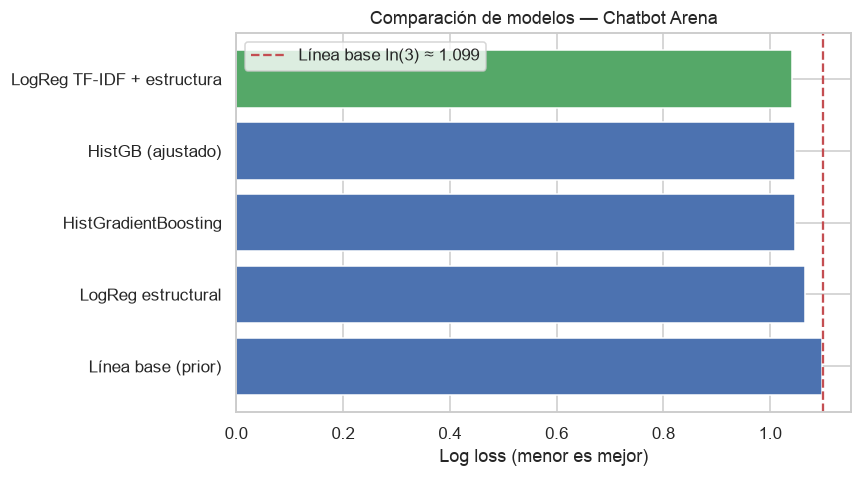

In [47]:
# (1) Comparación de log loss por modelo
fig, ax = plt.subplots(figsize=(8, 4.5))
orden = tabla.sort_values('log_loss', ascending=False)
colores = ['#4C72B0'] * len(orden)
colores[-1] = '#55A868'   # mejor modelo resaltado
ax.barh(orden['modelo'], orden['log_loss'], color=colores)
ax.axvline(np.log(3), ls='--', color='#C44E52', label='Línea base ln(3) ≈ 1.099')
ax.set_xlabel('Log loss (menor es mejor)')
ax.set_title('Comparación de modelos — Chatbot Arena')
ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'comparacion_logloss.png', dpi=150); plt.show()

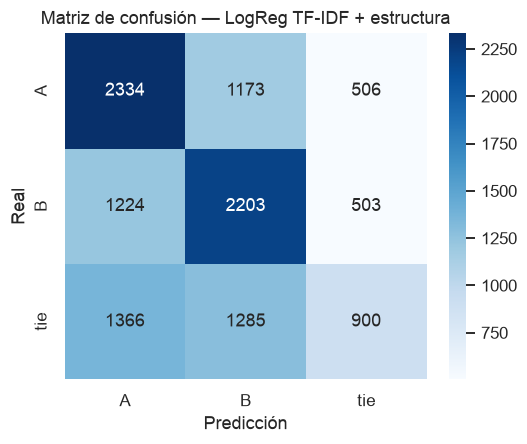

              precision    recall  f1-score   support

           A       0.47      0.58      0.52      4013
           B       0.47      0.56      0.51      3930
         tie       0.47      0.25      0.33      3551

    accuracy                           0.47     11494
   macro avg       0.47      0.47      0.45     11494
weighted avg       0.47      0.47      0.46     11494



In [48]:
# (2) Matriz de confusión del mejor modelo
mejor_nombre = tabla.iloc[0]['modelo']
modelos = {
    'Línea base (prior)': (base, NUM_FEATURES),
    'LogReg estructural': (logit_struct, NUM_FEATURES),
    'LogReg TF-IDF + estructura': (logit_texto, cols_texto),
    'HistGradientBoosting': (gb, NUM_FEATURES),
    'HistGB (ajustado)': (grid.best_estimator_, NUM_FEATURES),
}
mejor_modelo, mejor_cols = modelos[mejor_nombre]
proba_best = proba_ordenada(mejor_modelo, X_test[mejor_cols])
pred_best = np.array(CLASSES)[proba_best.argmax(axis=1)]
cm = confusion_matrix(y_test, pred_best, labels=CLASSES)
fig, ax = plt.subplots(figsize=(5, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title(f'Matriz de confusión — {mejor_nombre}')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'matriz_confusion.png', dpi=150); plt.show()
print(classification_report(y_test, pred_best, labels=CLASSES))

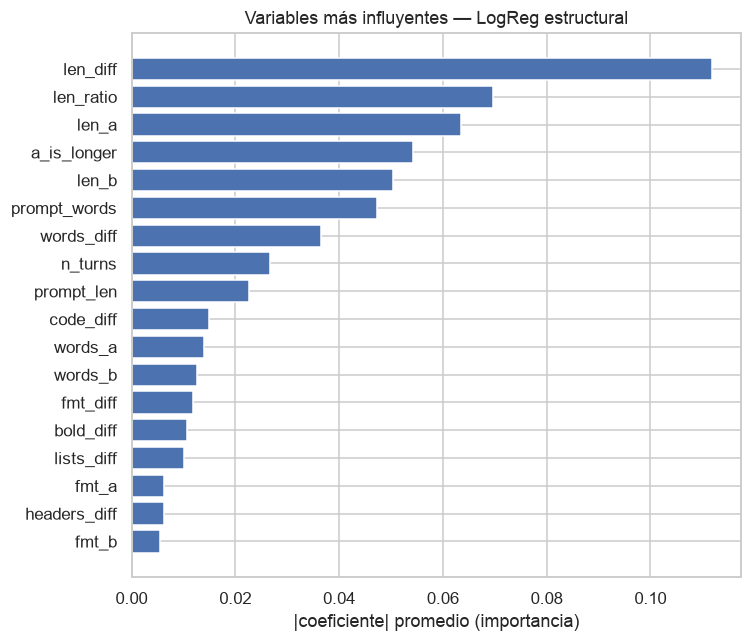

In [49]:
# (3) Importancia de variables (coeficientes de la LogReg estructural)
coefs = pd.DataFrame(logit_struct.named_steps['clf'].coef_, columns=NUM_FEATURES, index=logit_struct.named_steps['clf'].classes_)
imp = coefs.abs().mean(axis=0).sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(imp.index, imp.values, color='#4C72B0')
ax.set_xlabel('|coeficiente| promedio (importancia)')
ax.set_title('Variables más influyentes — LogReg estructural')
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'importancia_variables.png', dpi=150); plt.show()

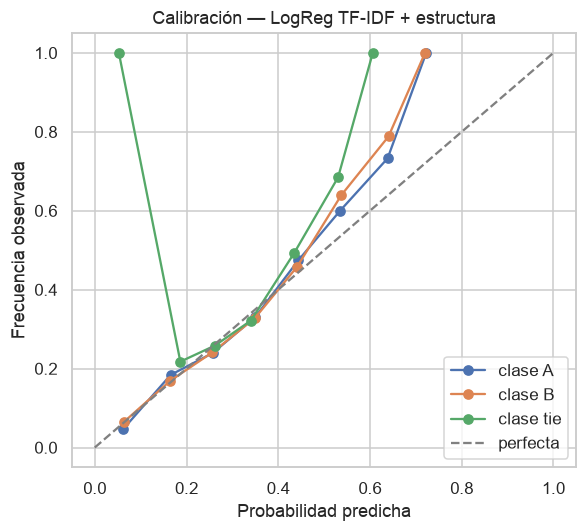

In [50]:
# (4) Curva de calibración (una por clase, uno-vs-resto) para el mejor modelo
fig, ax = plt.subplots(figsize=(5.5, 5))
for i, c in enumerate(CLASSES):
    frac_pos, media_pred = calibration_curve((y_test == c).astype(int), proba_best[:, i], n_bins=10)
    ax.plot(media_pred, frac_pos, marker='o', label=f'clase {c}')
ax.plot([0, 1], [0, 1], ls='--', color='gray', label='perfecta')
ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Frecuencia observada')
ax.set_title(f'Calibración — {mejor_nombre}'); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / 'calibracion.png', dpi=150); plt.show()

## 9. Guardado de modelos y predicciones
Se serializan los modelos entrenados y las probabilidades de prueba. La aplicación puede
cargar estos artefactos para clasificar entradas nuevas y mostrar el rendimiento sin
reentrenar.

In [51]:
joblib.dump(logit_struct, OUTPUT_DIR / 'modelo_logreg_estructural.joblib')
joblib.dump(logit_texto,  OUTPUT_DIR / 'modelo_logreg_tfidf.joblib')
joblib.dump(grid.best_estimator_, OUTPUT_DIR / 'modelo_histgb_ajustado.joblib')

pred_df = pd.DataFrame(proba_best, columns=[f'proba_{c}' for c in CLASSES])
pred_df['real'] = y_test
pred_df['pred'] = pred_best
pred_df.to_csv(OUTPUT_DIR / 'predicciones_prueba.csv', index=False)
print('Modelos y predicciones guardados en', OUTPUT_DIR.resolve())

Modelos y predicciones guardados en /Users/brandon/Documents/UVG/data/Proyecto2-Data-Science/notebooks/resultados_modelado


## 10. Discusión de resultados

**Mejor modelo.** La regresión logística con TF-IDF + variables estructurales obtuvo la menor
log loss en prueba (**1.0414**), seguida de HistGB ajustado (1.0460), HistGB sin ajustar (1.0470) y
la regresión logística estructural (1.0654). Frente a la línea base a priori (1.0972) la mejora es de
**0.056 nats (≈5%)**: real y consistente en los cuatro modelos, pero modesta, como anticipaba el EDA
(correlaciones |ρ| ≤ 0.24 entre las variables de superficie y el voto). La exactitud sube de 34.9%
(línea base) a 47.3%.

**Variables más influyentes.** En la LogReg estructural los coeficientes más grandes son `len_diff`,
`len_ratio`, `len_a` y `a_is_longer`, con signos opuestos para A y B. El modelo aprendió el mismo
**sesgo de verbosidad** del EDA. El formato (`fmt_diff`, `bold_diff`, `lists_diff`) pesa mucho menos
una vez que se controla por longitud. El rendimiento por grupos lo confirma: con TF-IDF la exactitud
es 54% cuando una respuesta es ≥2.7× más larga y baja a 42% cuando las longitudes son similares
(`rendimiento_por_longitud.png`).

**Clase más difícil: el empate.** La exhaustividad del empate es 0.25 (TF-IDF), 0.34 (HistGB) y
solo 0.05 (LogReg estructural, que casi nunca lo predice). HistGB es el que mejor reconoce empates
porque modela interacciones no lineales (p. ej. “longitudes parecidas *y* poco formato”).

**Ajuste de hiperparámetros.** `GridSearchCV` (3 pliegues, `neg_log_loss`) eligió
`learning_rate=0.05`, `max_iter=300`, `l2_regularization=1.0` (log loss CV 1.0513); con parada
temprana el modelo se detuvo en 43 iteraciones. La ganancia sobre HistGB por defecto es pequeña
(1.0470 → 1.0460). En la regresión logística con texto el ajuste decisivo fue la regularización fuerte
(`C=0.3`) y la **calibración sigmoide**: sin ella el modelo quedaba sobreconfiado y su log loss era peor
que la de la línea base pese a su buena exactitud.

**Desempeño contra costo.** El TF-IDF mejora 0.0046 de log loss sobre HistGB, pero tarda 83.5 s en
entrenar contra 6.2 s (y su archivo pesa 7.5 MB contra 0.5 MB). El contenido del texto aporta, pero
poco con una representación de bolsa de palabras; para mejoras grandes haría falta un transformer
ajustado sobre la tripleta (prompt, A, B).

**Modelo elegido.** Para la aplicación se usan los tres modelos, que el usuario puede comparar. El
modelo principal es **LogReg TF-IDF + estructura** (mejor log loss y probabilidades bien calibradas).
**HistGB ajustado** queda como alternativa ligera, casi igual de buena y mejor para detectar empates.
